In [1]:
from ctypes import *

import os


import time

import matplotlib.pyplot as plt

import pyvisa

from scipy.optimize import curve_fit

import scipy.fft as fft

from Instruments.atsapi import *

from Routines.alazar_ats9870_homodyne import *

import shutil

from datetime import datetime

In [2]:

rm = pyvisa.ResourceManager()

print(rm.list_resources())

('USB0::0x2EC7::0x9130::800885011797670040::INSTR', 'ASRL1::INSTR', 'ASRL3::INSTR', 'GPIB0::10::INSTR', 'GPIB0::12::INSTR', 'GPIB0::15::INSTR', 'GPIB0::21::INSTR', 'GPIB0::22::INSTR', 'GPIB0::27::INSTR')


In [74]:
triggersource_addr = "GPIB0::12::INSTR"

alazarboard = Board()

rm = pyvisa.ResourceManager()

#awg = rm.open_resource(triggersource_addr)

print(alazarboard.getBoardKind())

print(alazarboard.getChannelInfo())

print(alazarboard.getBoardRevision())

13
(c_ulong(268435456), c_ubyte(8))
(c_byte(1), c_byte(6))


In [75]:
print(alazarboard.getStatus())

print(alazarboard.getMaxRecordsCapable(256))

2
c_ulong(986895)


In [69]:
def to_voltage(raw):
    return (raw/255.0)*4 - 2

In [77]:
bytesPerSample = 1
num_samples = int(3E6)
num_records = 1
input_range = INPUT_RANGE_PM_200_MV
bytesPerBuffer = num_records*num_samples*bytesPerSample

num_channels = 2

pre_trigger_samples = 0
post_trigger_samples = num_samples

sample_rate = SAMPLE_RATE_1MSPS

sample_rate_compute = 1000000000
print(bytesPerBuffer)

3000000


In [78]:
alazarboard.setCaptureClock(INTERNAL_CLOCK, sample_rate, CLOCK_EDGE_RISING, 0)


alazarboard.inputControlEx(CHANNEL_A, DC_COUPLING, INPUT_RANGE_PM_400_MV, IMPEDANCE_50_OHM) #Channel 2, DC coupling, input range, 50 ohm impedance

alazarboard.inputControlEx(CHANNEL_B, DC_COUPLING, INPUT_RANGE_PM_400_MV, IMPEDANCE_50_OHM)


alazarboard.setTriggerOperation(TRIG_ENGINE_OP_J, TRIG_ENGINE_J, TRIG_EXTERNAL, TRIGGER_SLOPE_POSITIVE, 150, TRIG_ENGINE_K, TRIG_DISABLE, TRIGGER_SLOPE_POSITIVE, 128)

In [79]:
alazarboard.setRecordSize(
    pre_trigger_samples, #Pretrigger samples
    post_trigger_samples #posttrigger samples
)

alazarboard.setRecordCount(
    num_records #record count (number of triggers) per acquisition
)

alazarboard.setExternalTrigger(DC_COUPLING, ETR_5V)

triggerTimeout_sec = 0
#triggerTimeout_clocks = int(triggerTimeout_sec / 10e-6 + 0.5)
alazarboard.setTriggerTimeOut(0)

#triggerDelay_sec = 0.341E-7
#triggerDelay_samples = int(triggerDelay_sec * sample_rate_compute + 0.5)
#alazarboard.setTriggerDelay(triggerDelay_samples)


In [80]:
# mix.write("SOUR:FUNC DC")

# mix.write("SOUR:VOLT:OFFS 0.028")

# trig.write("OUTP ON")

# lo.write("FREQ 2.22899E9")


time.sleep(1)

start = time.perf_counter()

alazarboard.startCapture()

while not enter_pressed():
    if not alazarboard.busy():
        # Acquisition is done
        break
    time.sleep(10e-3)



finish = time.perf_counter()

duration = finish - start

print(duration)

print("Done")

17.563284400006523
Done


In [81]:
#awg.write("OUTP OFF")

buffer_channel_a = DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer + 16) #entire acquisition is called a buffer - this function sets the buffer size

alazarboard.read(
    CHANNEL_A, 
    buffer_channel_a.addr,
    bytesPerSample,
    1,
    -pre_trigger_samples,
    num_samples
)

bufa = buffer_channel_a.buffer[:num_samples]

buffer_channel_b = DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer + 16)

alazarboard.read(
    CHANNEL_B,
    buffer_channel_b.addr,
    bytesPerSample,
    1,
    -pre_trigger_samples,
    num_samples
)

bufb = buffer_channel_b.buffer[:num_samples]




In [82]:
voltage_a = to_voltage(bufa)

voltage_b = to_voltage(bufb)

total_time = num_samples/sample_rate

time_list = np.arange(num_samples)/sample_rate_compute

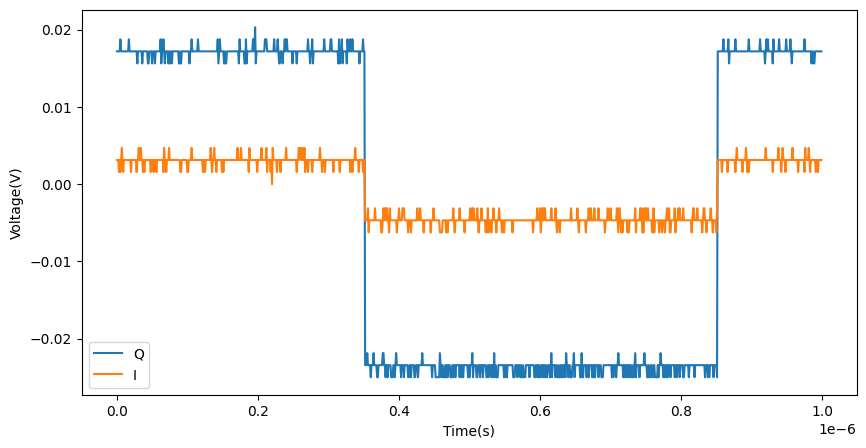

In [83]:
plt.figure(figsize = (10, 5))

plt.plot(time_list[:1000], voltage_a[:1000], label = "Q")
plt.plot(time_list[:1000], voltage_b[:1000], label = "I")

plt.xlabel("Time(s)")

plt.ylabel("Voltage(V)")
plt.legend()
plt.show()


#plt.scatter(time_list, voltage_a)
#plt.scatter(time_list, voltage_b)


In [204]:
print(voltage_a[:100])

[ 0.0515625  0.05       0.0515625 -0.0453125 -0.0453125 -0.0453125
 -0.04375   -0.0453125 -0.04375   -0.0453125 -0.04375   -0.0453125
 -0.0453125 -0.04375   -0.0453125 -0.04375   -0.0453125 -0.04375
 -0.0453125 -0.04375   -0.0453125 -0.0453125 -0.04375   -0.04375
 -0.0453125 -0.0453125 -0.0453125 -0.04375   -0.0453125 -0.04375
 -0.0421875 -0.04375   -0.04375   -0.0453125 -0.0453125 -0.0453125
 -0.0453125 -0.0453125 -0.0453125 -0.0453125 -0.04375   -0.04375
 -0.0453125 -0.0453125 -0.04375   -0.0453125 -0.0453125 -0.0453125
 -0.0453125 -0.0453125 -0.0453125 -0.0453125 -0.0453125 -0.0453125
 -0.04375   -0.04375   -0.0453125 -0.04375   -0.04375   -0.04375
 -0.0453125 -0.04375   -0.04375   -0.0453125 -0.04375   -0.0453125
 -0.0453125 -0.04375   -0.0453125 -0.04375   -0.04375   -0.0453125
 -0.0453125 -0.0453125 -0.0453125 -0.0421875 -0.0453125 -0.04375
 -0.0453125 -0.0453125 -0.0453125 -0.04375   -0.04375   -0.04375
 -0.0453125 -0.04375   -0.0453125 -0.04375   -0.0453125 -0.04375
 -0.0453125

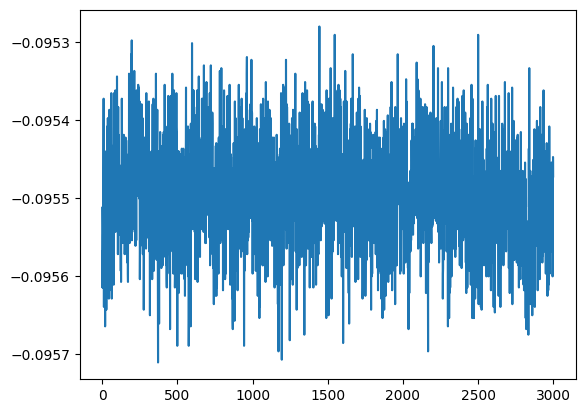

In [205]:
def return_chunk_average(chunk_a, chunk_b):

    chunk_a_average = np.average(chunk_a)

    chunk_b_average = np.average(chunk_b)

    return chunk_a_average - chunk_b_average


average_voltage = []

for chunk in range(0, len(voltage_a), 1000):
    chunk_a = voltage_a[chunk+30:chunk + 470]
    chunk_b = voltage_a[chunk+530:chunk+970]

    averaged = return_chunk_average(chunk_a, chunk_b)

    average_voltage.append(averaged)

plt.plot(average_voltage)



[-0.2       -0.2       -0.2       -0.2       -0.2       -0.2
 -0.2       -0.2       -0.2       -0.2       -0.2       -0.2
 -0.2       -0.2       -0.2       -0.2       -0.2       -0.2
 -0.2       -0.2       -0.2       -0.2       -0.2       -0.2
 -0.2       -0.2       -0.2        0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375  0.1984375
  0.1984375  0.1984

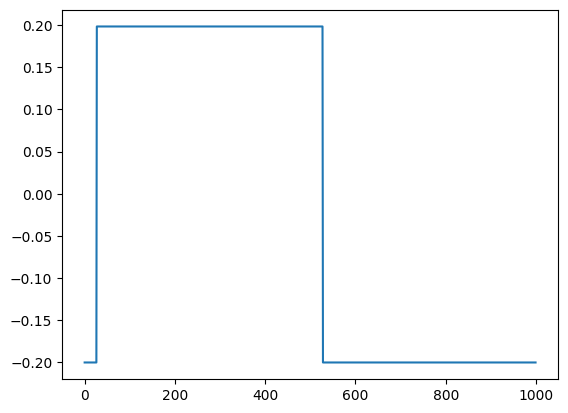

In [165]:
plt.plot(voltage_a[len(voltage_a) - 1000:])

print(voltage_a[len(voltage_a) - 1000:])

In [ ]:
print(len(voltage_a))

C:\Users\crow104\AppData\Local\Temp\ipykernel_10960\1361647623.py:3: RuntimeWarning: divide by zero encountered in divide
  phase_measured = np.arctan(voltage_a/voltage_b)


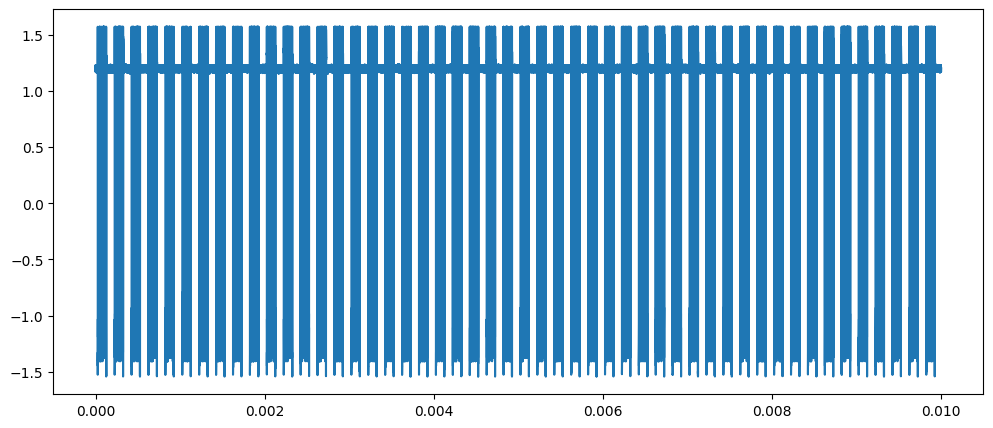

In [125]:
plt.figure(figsize = (12, 5))

phase_measured = np.arctan(voltage_a/voltage_b)


plt.plot(time_list, phase_measured)

Text(0, 0.5, 'Q')

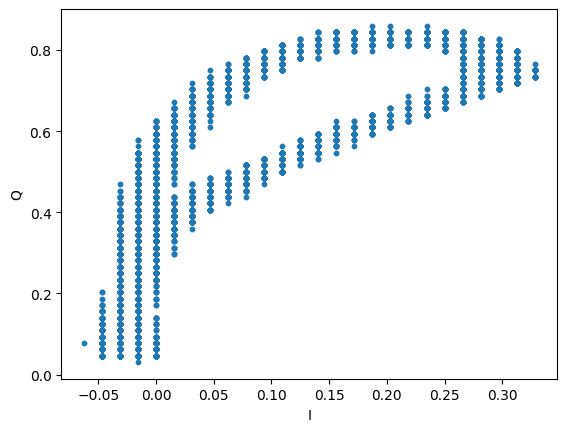

In [126]:
plt.scatter(voltage_b, voltage_a, s = 10)

plt.xlabel("I")
plt.ylabel("Q")

In [291]:
rm = pyvisa.ResourceManager()
print(rm.list_resources())

lo_addr = "GPIB0::27::INSTR"

mixQ_addr = "GPIB0::12::INSTR"
mixI_addr = "GPIB0::21::INSTR"

trig_addr = "GPIB0::10::INSTR"

lo = rm.open_resource(lo_addr)
mixI = rm.open_resource(mixI_addr)
mixQ = rm.open_resource(mixQ_addr)
trig = rm.open_resource(trig_addr)

('USB0::0x2EC7::0x9130::800885011797670040::INSTR', 'ASRL1::INSTR', 'ASRL3::INSTR', 'GPIB0::10::INSTR', 'GPIB0::12::INSTR', 'GPIB0::21::INSTR', 'GPIB0::22::INSTR', 'GPIB0::27::INSTR')


In [353]:
bytesPerSample = 1



num_channels = 2


num_samples = int(100E6)
num_records = 1
input_range = INPUT_RANGE_PM_40_MV
bytesPerBuffer = num_records*num_samples*bytesPerSample*num_channels

buffersPerAcquisition = 3


recordsPerAcquisition = num_records*buffersPerAcquisition



pre_trigger_samples = 0
post_trigger_samples = num_samples

sample_rate = SAMPLE_RATE_100MSPS

sample_rate_compute = 100000000


alazarboard.setCaptureClock(INTERNAL_CLOCK, sample_rate, CLOCK_EDGE_RISING, 0)


alazarboard.inputControlEx(CHANNEL_A, DC_COUPLING, INPUT_RANGE_PM_200_MV, IMPEDANCE_50_OHM) #Channel 2, DC coupling, input range, 50 ohm impedance

alazarboard.inputControlEx(CHANNEL_B, DC_COUPLING, INPUT_RANGE_PM_200_MV, IMPEDANCE_50_OHM)


alazarboard.setTriggerOperation(TRIG_ENGINE_OP_J, TRIG_ENGINE_J, TRIG_EXTERNAL, TRIGGER_SLOPE_POSITIVE, 127, TRIG_ENGINE_K, TRIG_DISABLE, TRIGGER_SLOPE_POSITIVE, 128)

alazarboard.setRecordSize(
    pre_trigger_samples, #Pretrigger samples
    post_trigger_samples #posttrigger samples
)

alazarboard.setExternalTrigger(DC_COUPLING, ETR_5V)


In [304]:
buffcount = 4

bufflist = []

for buffer in range(buffcount):
    bufflist.append(DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer))


In [305]:
print(type(channels))
alazarboard.beforeAsyncRead(CHANNEL_A | CHANNEL_B,
                        -pre_trigger_samples,
                        num_samples,
                        num_records,
                        recordsPerAcquisition,
                        ADMA_EXTERNAL_STARTCAPTURE | ADMA_TRADITIONAL_MODE) #enables both channes in dualport autodma traditional mode



mixQ.write("SOUR:FUNC SQU")
mixQ.write("SOUR:FREQ 5E3")

mixQ.write("SOUR:VOLT 1.0")
mixQ.write("SOUR:VOLT:OFFS -0.061")
time.sleep(0.01)
mixI.write("SOUR:FUNC DC")
mixI.write("SOUR:VOLT:OFFS 0.0132")
time.sleep(0.01)
mixI.write("OUTP ON")
mixQ.write("OUTP ON")

time.sleep(0.01)
trig.write("SOUR:FUNC SQU")
trig.write("SOUR:FREQ 5")
trig.write("SOUR:VOLT 0.5")
trig.write("SOUR:VOLT:OFFS 0.5")
time.sleep(0.01)
trig.write("OUTP ON")

os.mkdir(r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\daq_iceT\noisefloor")

for buffer in bufflist:
        alazarboard.postAsyncBuffer(buffer.addr, buffer.size_bytes)

<class 'list'>


In [306]:

savedir = r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\daq_iceT\noisefloor"

start = time.perf_counter() # Keep track of when acquisition started
try:
    alazarboard.startCapture() # Start the acquisition
    print("Capturing %d buffers. Press <enter> to abort" %
            buffersPerAcquisition)
    buffersCompleted = 0
    bytesTransferred = 0
    recordsCompleted = 0
    while (buffersCompleted < buffersPerAcquisition and not
            enter_pressed()):
        # Wait for the buffer at the head of the list of available
        # buffers to be filled by the board.
        buffer = bufflist[buffersCompleted % len(bufflist)]
        alazarboard.waitAsyncBufferComplete(buffer.addr, timeout_ms= 5000)
        buffersCompleted += 1
        recordsCompleted += 1
        bytesTransferred += buffer.size_bytes

        # TODO: Process sample data in this buffer. Data is available
        # as a NumPy array at buffer.buffer

        # NOTE:
        #
        # While you are processing this buffer, the board is already
        # filling the next available buffer(s).
        #
        # You MUST finish processing this buffer and post it back to the
        # board before the board fills all of its available DMA buffers
        # and on-board memory.
        #
        # Samples are arranged in the buffer as follows:
        # S0A, S0B, ..., S1A, S1B, ...
        # with SXY the sample number X of channel Y.
        #
        # Sample code are stored as 8-bit values.
        #
        # Sample codes are unsigned by default. As a result:
        # - 0x00 represents a negative full scale input signal.
        # - 0x80 represents a ~0V signal.
        # - 0xFF represents a positive full scale input signal.
        # Optionaly save data to file

        shapeddata = buffer.buffer.reshape([num_records, 2, num_samples])

        channelA = shapeddata[:, 0, :].flatten() #flattening my data into a single array
        channelB = shapeddata[:, 1, :].flatten() #flattening my data into a single array


        out = np.column_stack([channelA, channelB])
        np.savetxt(r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\daq_iceT\noisefloor" + "\\"+ f"data{buffersCompleted}.csv", out, delimiter= ',', header = "ChannelA, CHannelB", fmt = "%d")

        

        # Add the buffer to the end of the list of available buffers.
        alazarboard.postAsyncBuffer(buffer.addr, buffer.size_bytes)

        duration = time.perf_counter() - start
finally:
    alazarboard.abortAsyncRead()



Capturing 30 buffers. Press <enter> to abort


In [ ]:
lo_addr = "GPIB0::27::INSTR"

mix_addr = "GPIB0::12::INSTR"

#trig_addr = "GPIB0::10::INSTR"

lo = rm.open_resource(lo_addr)
#mix = rm.open_resource(mix_addr)
trig = rm.open_resource(trig_addr)

In [71]:
alazarboard = Board()

print(alazarboard.getBoardKind())

print(alazarboard.getChannelInfo())

print(alazarboard.getBoardRevision())

13
(c_ulong(268435456), c_ubyte(8))
(c_byte(1), c_byte(6))


In [72]:
bytesPerSample = 1
num_samples = 10000
num_records = 1
input_range = INPUT_RANGE_PM_40_MV
bytesPerBuffer = num_records*num_samples*bytesPerSample

num_channels = 2

pre_trigger_samples = 0
post_trigger_samples = num_samples

sample_rate = SAMPLE_RATE_100MSPS

sample_rate_compute = 100000000
print(bytesPerBuffer)

10000


In [73]:
alazarboard.setCaptureClock(INTERNAL_CLOCK, sample_rate, CLOCK_EDGE_RISING, 0)


alazarboard.inputControlEx(CHANNEL_A, DC_COUPLING, INPUT_RANGE_PM_400_MV, IMPEDANCE_50_OHM) #Channel 2, DC coupling, input range, 50 ohm impedance

alazarboard.inputControlEx(CHANNEL_B, DC_COUPLING, INPUT_RANGE_PM_400_MV, IMPEDANCE_50_OHM)


alazarboard.setTriggerOperation(TRIG_ENGINE_OP_J, TRIG_ENGINE_J, TRIG_EXTERNAL, TRIGGER_SLOPE_POSITIVE, 150, TRIG_ENGINE_K, TRIG_DISABLE, TRIGGER_SLOPE_POSITIVE, 128)

alazarboard.setExternalTrigger(DC_COUPLING, ETR_5V)

In [74]:
alazarboard.setRecordSize(
    pre_trigger_samples, #Pretrigger samples
    post_trigger_samples #posttrigger samples
)

alazarboard.setRecordCount(
    num_records #record count (number of triggers) per acquisition
)

In [75]:
def alazarCapture(board):
    start = time.perf_counter()
    board.startCapture()

    while not enter_pressed():
        if not alazarboard.busy():
        # Acquisition is done
            break
        time.sleep(10e-3)
    print(f"{time.perf_counter() - start} seconds")    

def alazarDataAcquisition(board, buffer_channel_a, buffer_channel_b, num_samples):
    board.read(
        CHANNEL_A, 
        buffer_channel_a.addr,
        bytesPerSample,
        1,
        -pre_trigger_samples,
        num_samples
    )
    bufa = buffer_channel_a.buffer[:num_samples]

    board.read(
        CHANNEL_B,
        buffer_channel_b.addr,
        bytesPerSample,
        1,
        -pre_trigger_samples,
        num_samples
    )
    bufb = buffer_channel_b.buffer[:num_samples]

    return bufa, bufb

In [79]:
mix = rm.open_resource("GPIB0::10::INSTR")
#trig = rm.open_resource("GPIB0::21::INSTR")
lo = rm.open_resource("GPIB0::27::INSTR")

mix.write("SOUR:FUNC DC")
mix.write("SOUR:VOLT:OFFS 1.0")
mix.write("OUTP ON")

time.sleep(1)
#Setting the mixer to a constant 1.0V bias

TTL_pulse_configuration(address= "GPIB0::15::INSTR", trigger_rate= 5)

time.sleep(1)
#Configuring the trigger - 5 Hz square volt oscillations to capture data on the rising slop when initialized

f_start = 2.00E9

f_stop = 3.00E9

frequencies = np.linspace(f_start, f_stop, 1001)

i_raw = []
q_raw = []

for f in frequencies:
    lo.write(f"FREQ {f}")
    lo.write("ENBR 1")
    time.sleep(0.1)

    #print(lo.query("FREQ?"))
    #lo.write("OUTP OFF")
    alazarCapture(alazarboard)
    print("Captured")
    time.sleep(0.1)
    lo.write("ENBR 0")
    time.sleep(0.1)
    bufferA = DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer + 16)
    bufferB = DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer + 16)
    qarray, iarray = alazarDataAcquisition(alazarboard, bufferA, bufferB, num_samples)
    time.sleep(0.1)
    q_raw.append(np.average(qarray))
    i_raw.append(np.average(iarray))

    



TM 0; TR 0,5; TZ 4,0; OM 4,0; DT 2,1,0.0001; DT 3,2,0.0001
0.0001
TTL confirmed
0.12621060013771057 seconds
Captured
0.1984002001117915 seconds
Captured
0.1897195999044925 seconds
Captured
0.19882300007157028 seconds
Captured
0.1979371001943946 seconds
Captured
0.18770090001635253 seconds
Captured
0.19670239998959005 seconds
Captured
0.20032580010592937 seconds
Captured
0.1881409001071006 seconds
Captured
0.1981528999749571 seconds
Captured
0.19729840010404587 seconds
Captured
0.18924349988810718 seconds
Captured
0.2005181999411434 seconds
Captured
0.19019019999541342 seconds
Captured
0.19908539997413754 seconds
Captured
0.1887424997985363 seconds
Captured
0.20024699997156858 seconds
Captured
0.18839410017244518 seconds
Captured
0.19622679986059666 seconds
Captured
0.19026179984211922 seconds
Captured
0.19958220003172755 seconds
Captured
0.18961109989322722 seconds
Captured
0.19952120003290474 seconds
Captured
0.1906322999857366 seconds
Captured
0.19737419998273253 seconds
Captured
0.1

1001 1001 1001


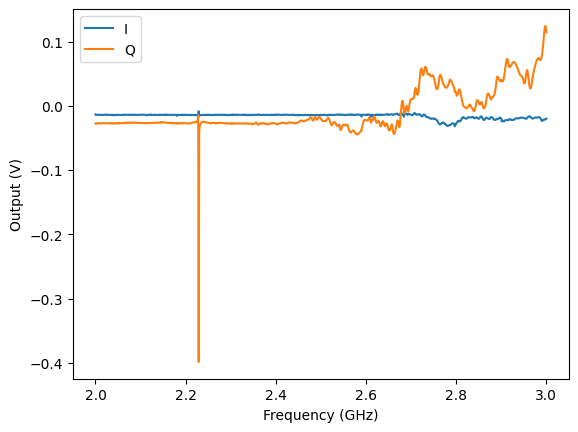

In [80]:
print(len(frequencies), len(i_raw), len(q_raw))

volt_i = to_voltage(np.array(i_raw), bounds = 1)
volt_q = to_voltage(np.array(q_raw), bounds = 1)

plt.plot(frequencies/1E9, volt_i, label = "I ")
plt.plot(frequencies/1E9, volt_q, label = "Q")

plt.xlabel("Frequency (GHz)")
plt.ylabel("Output (V)")

plt.legend()
plt.show()

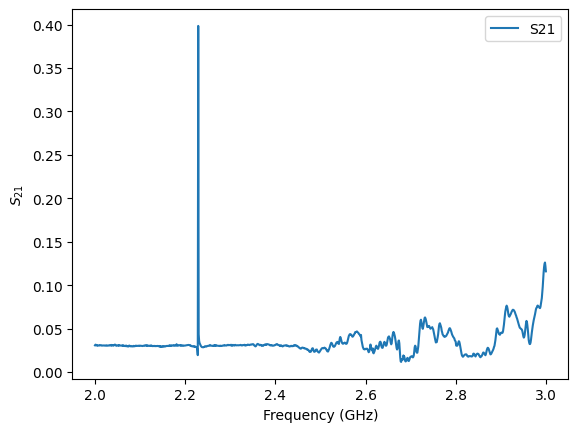

2229000000.0


In [81]:
output_s21 = np.sqrt(volt_i**2 + volt_q**2)

plt.plot(frequencies/1E9, output_s21, label = "S21")
plt.xlabel("Frequency (GHz)")
plt.ylabel("$S_{21}$")

plt.legend()
plt.show()

print(frequencies[np.argmax(output_s21)])

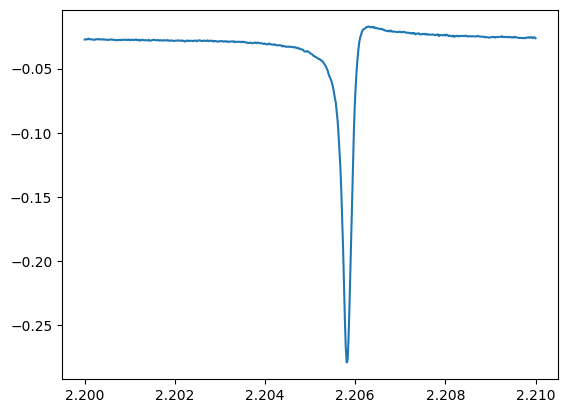

In [50]:
plt.plot(frequencies/1E9, np.arctan(volt_q,volt_i))

In [51]:
print(frequencies[np.argmax(output_s21)])

2205811623.246493


<>:5: SyntaxWarning: invalid escape sequence '\p'
<>:5: SyntaxWarning: invalid escape sequence '\p'
C:\Users\crow104\AppData\Local\Temp\ipykernel_10960\897232988.py:5: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel("$\phi$ (rad)")


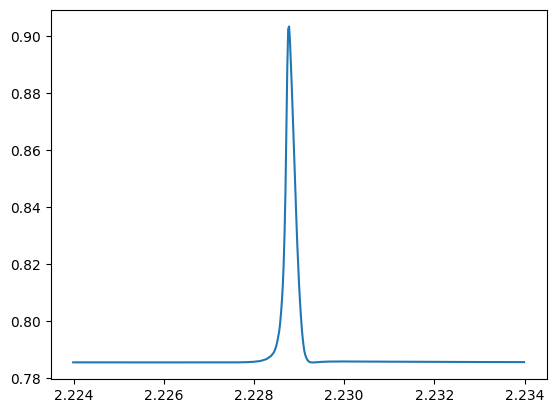

Text(0, 0.5, '$\\phi$ (rad)')

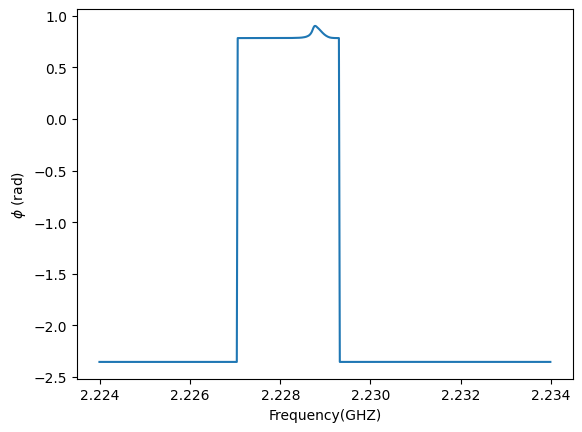

In [250]:
plt.plot(frequencies/1E9, np.arctan(volt_q/volt_i))
plt.show()
plt.plot(frequencies/1E9, np.arctan2(volt_q, volt_i))
plt.xlabel("Frequency(GHZ)")
plt.ylabel("$\phi$ (rad)")

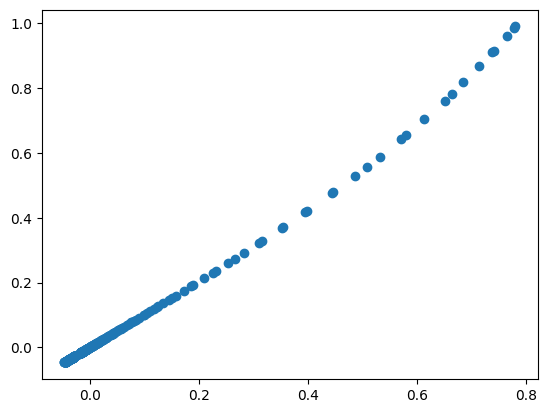

In [251]:
plt.scatter(volt_i, volt_q)

In [260]:
def Lorentzian(x, x0, a, c, g):
    return a/(g*(1 + (x - x0)**2/g**2)) + c


params, cov = curve_fit(Lorentzian, frequencies, output_s21, 
                           p0 = [np.average(frequencies), 1, 0, 0.2*(np.max(frequencies) - np.min(frequencies))],
                           maxfev = 100000, bounds = ((np.average(frequencies) - 0.5, 0, -np.inf, 0), (np.average(frequencies) + 0.5, 1.5, np.inf, 2 * (np.max(frequencies) - np.min(frequencies)))))

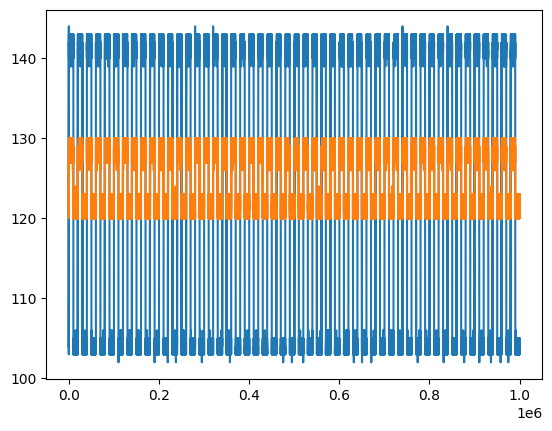

In [347]:
filepath = r"C:\Users\crow104\Desktop\IceT_SD\RealTimeGrowthMonitor\IceT_SD\daq_iceT\noisefloor\data16.csv"


data = np.loadtxt(filepath, delimiter = ',', skiprows= 1)

Q_raw = data[:,0]
I_raw = data[:,1]

highQ = Q_raw[Q_raw >= 120]
lowQ = Q_raw[Q_raw < 120]
highI = I_raw[I_raw >= 125]
lowI = I_raw[I_raw < 125]

plt.plot(Q_raw)
plt.plot(I_raw)

In [323]:
averaged_Q = (lowQ + highQ[:len(lowQ)])/2

low_average = averaged_Q

high_average = averaged_Q

additional_average = (highQ[len(lowQ):] + lowQ[:len(highQ) - len(lowQ)])/2

new_average = np.append(low_average, high_average)
new_average = np.append(new_average, additional_average)

In [325]:
averaged_I = (lowI + highI[:len(lowI)])/2

low_averageI = averaged_I

high_averageI = averaged_I

additional_averageI = (highI[len(lowI):] + lowI[:len(highI) - len(lowI)])/2

new_averageI = np.append(low_averageI, high_averageI)
new_averageI = np.append(new_averageI, additional_averageI)

In [326]:
volt_averageQ = to_voltage(new_average)

volt_averageI = to_voltage(new_averageI)


downsampledQ = volt_averageQ[::10]
downsampledI = volt_averageI[::10]

print(len(downsampledQ), len(downsampledI))

100000 100000


In [2]:
def load_split_average(file):
    
    data = np.loadtxt(filepath, delimiter = ',', skiprows= 1)

    Q_raw = data[:,0]
    I_raw = data[:,1]

    highQ = Q_raw[Q_raw >= 120]
    lowQ = Q_raw[Q_raw < 120]
    highI = I_raw[I_raw >= 125]
    lowI = I_raw[I_raw < 125]

    if (len(highQ) >= len(lowQ)):
        averaged_Q = (lowQ + highQ[:len(lowQ)])/2
        additional_averageQ = (highQ[len(lowQ):] + lowQ[:len(highQ) - len(lowQ)])/2

    else:
        averaged_Q = (highQ + lowQ[:len(highQ)])/2
        additional_averageQ = (lowQ[len(highQ):] + highQ[:len(lowQ) - len(highQ)])/2

    low_averageQ = averaged_Q
    high_averageQ = averaged_Q

    new_averageQ = np.append(low_averageQ, high_averageQ)
    new_averageQ = np.append(new_averageQ, additional_averageQ)


    if (len(highI) >= len(lowI)):
        averaged_I = (lowI + highQ[:len(lowI)])/2
        additional_averageI = (highI[len(lowI):] + lowI[:len(highI) - len(lowI)])/2

    else:
        averaged_I = (highI + lowI[:len(highI)])/2
        additional_averageI = (lowI[len(highI):] + highI[:len(lowI) - len(highI)])/2

    low_averageI = averaged_I
    high_averageI = averaged_I

    new_averageI = np.append(low_averageI, high_averageI)
    new_averageI = np.append(new_averageI, additional_averageI)

    return new_averageI, new_averageQ


def to_voltage(data, bounds):
    return(data/256.0)*(2*bounds) - bounds

def to_phase(Idata, Qdata):
    return np.arctan2(Qdata, Idata)

def return_psd(data, xf, yf):
    return (yf**2)/(len(data)*(xf[2] - xf[1]))

def downsampledIQ(I_data, Q_data, factor):
    return I_data[::factor], Q_data[::factor]


In [9]:
alazarboard = Board()

rm = pyvisa.ResourceManager()
print(rm.list_resources())

lo_addr = "GPIB0::27::INSTR"

mixQ_addr = "GPIB0::10::INSTR"
mixI_addr = "GPIB0::21::INSTR"

trig_addr = "GPIB0::15::INSTR"

lo = rm.open_resource(lo_addr)
mixI = rm.open_resource(mixI_addr)
mixQ = rm.open_resource(mixQ_addr)
trig = rm.open_resource(trig_addr)

bytesPerSample = 1
num_channels = 2


num_samples_per_buffer = int(10E6)
acquisitiontime_sec = 30
bytesPerBuffer = num_samples_per_buffer*bytesPerSample*num_channels


sample_rate = SAMPLE_RATE_100MSPS

sample_rate_compute = 100000000

samplesPerAcquisition = int(sample_rate_compute*acquisitiontime_sec)

buffersPerAcquisition = samplesPerAcquisition//num_samples_per_buffer

print(samplesPerAcquisition, buffersPerAcquisition)


alazarboard.setCaptureClock(EXTERNAL_CLOCK_10MHz_REF, int(1E9), CLOCK_EDGE_RISING, 10)


alazarboard.inputControlEx(CHANNEL_A, DC_COUPLING, INPUT_RANGE_PM_2_V, IMPEDANCE_50_OHM) #Channel 2, DC coupling, input range, 50 ohm impedance

alazarboard.inputControlEx(CHANNEL_B, DC_COUPLING, INPUT_RANGE_PM_2_V, IMPEDANCE_50_OHM)


alazarboard.setTriggerOperation(TRIG_ENGINE_OP_J, TRIG_ENGINE_J, TRIG_EXTERNAL, TRIGGER_SLOPE_POSITIVE, 140, TRIG_ENGINE_K, TRIG_DISABLE, TRIGGER_SLOPE_POSITIVE, 128)


alazarboard.setExternalTrigger(DC_COUPLING, ETR_5V)

alazarboard.setTriggerTimeOut(0)

alazarboard.setTriggerDelay(0)

buffcount = 150

bufflist = []

for buffer in range(buffcount):
    bufflist.append(DMABuffer(alazarboard.handle, c_uint8, bytesPerBuffer))

('USB0::0x2EC7::0x9130::800885011797670040::INSTR', 'ASRL1::INSTR', 'ASRL3::INSTR', 'GPIB0::10::INSTR', 'GPIB0::12::INSTR', 'GPIB0::15::INSTR', 'GPIB0::21::INSTR', 'GPIB0::22::INSTR', 'GPIB0::27::INSTR')
3000000000 300


In [10]:
print(type(channels))
alazarboard.beforeAsyncRead(CHANNEL_A | CHANNEL_B,
                        0,
                        num_samples_per_buffer,
                        1,
                        0x7FFFFFFF,
                        ADMA_EXTERNAL_STARTCAPTURE | ADMA_TRIGGERED_STREAMING) #enables both channes in dualport autodma traditional mode


trig.write("TM 0; TR 0,0.03125; TZ 2,0; TZ 3,0; TZ 4,0; DT 2,1,100E-6; DT 3,2, 100E-6; OM 4,0")
mixQ.write("SOUR:FUNC SQU")
mixQ.write("SOUR:FREQ 1E3")
mixQ.write("SOUR:VOLT 1.0")
mixQ.write("SOUR:VOLT:OFFS -0.061")
mixQ.write("PHAS 49.00")
time.sleep(0.01)
mixQ.write("BURST:STAT ON")
mixQ.write("BURST:NCYCLES 30000")
mixQ.write("TRIG:SOUR EXT")
mixQ.write("TRIG:SLOP POS")
# mixQ.write("TRIG:SOUR INT")
# mixQ.write("BURST:STAT OFF")
time.sleep(0.01)
mixI.write("SOUR:FUNC DC")
mixI.write("SOUR:VOLT:OFFS 0.0132")
time.sleep(0.01)
lo.write("AMPL 16")
time.sleep(0.01)
mixI.write("OUTP ON")
mixQ.write("OUTP ON")

time.sleep(0.01)


os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01202025_10dbm", exist_ok= True)

for buffer in bufflist:
        alazarboard.postAsyncBuffer(buffer.addr, buffer.size_bytes)

<class 'list'>


In [11]:

savedir = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01202025_10dbm"

start = time.perf_counter() # Keep track of when acquisition started
try:
    alazarboard.startCapture() # Start the acquisition
    print("Capturing %d buffers. Press <enter> to abort" %
            buffersPerAcquisition)
    buffersCompleted = 0
    bytesTransferred = 0
    while (buffersCompleted < buffersPerAcquisition and not
            enter_pressed()):
        # Wait for the buffer at the head of the list of available
        # buffers to be filled by the board.
        buffer = bufflist[buffersCompleted % len(bufflist)]
        alazarboard.waitAsyncBufferComplete(buffer.addr, timeout_ms= 40000)
        buffersCompleted += 1
        bytesTransferred += buffer.size_bytes

        #shapeddata = buffer.buffer.reshape([2, num_samples_per_buffer])

        #channelA = shapeddata[0, :].flatten() #flattening my data into a single array
        #channelB = shapeddata[1, :].flatten() #flattening my data into a single array


        out = buffer.buffer
        out.tofile(savedir + "\\"+ f"data{buffersCompleted}.bin")

        

        # Add the buffer to the end of the list of available buffers.
        alazarboard.postAsyncBuffer(buffer.addr, buffer.size_bytes)

        duration = time.perf_counter() - start
finally:
    alazarboard.abortAsyncRead()



Capturing 300 buffers. Press <enter> to abort


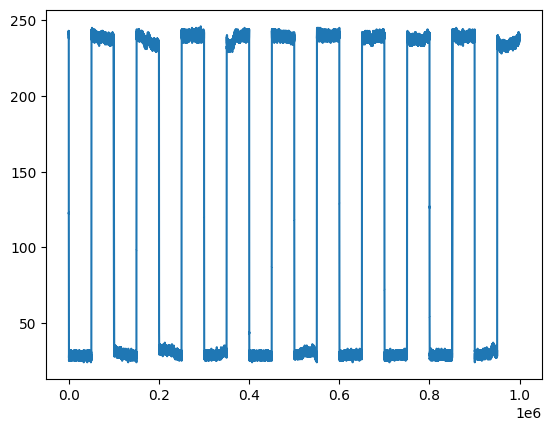

In [56]:
data = np.fromfile(r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\testneon_02262026\data298.bin", dtype = np.uint8).reshape([2, int(10E6)])

plt.plot(data[0, int(000E3):int(1000E3)])
plt.show()

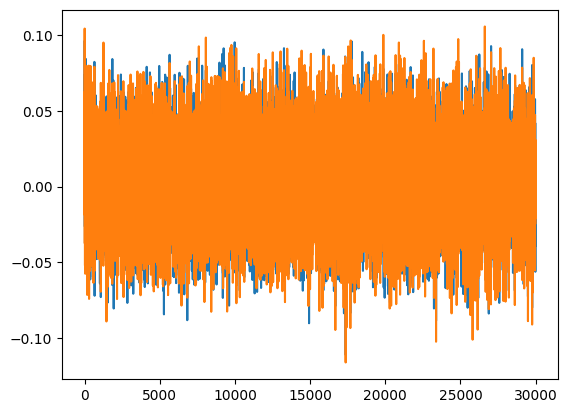

In [7]:
def return_chunk_average(chunk_a, chunk_b):

    chunk_a_average = np.average(chunk_a)

    chunk_b_average = np.average(chunk_b)

    return chunk_a_average - chunk_b_average


downsampledIcomplete = []
downsampledQcomplete = []
sample_rate_compute = int(100E6)
choppingtone = int(1E3)
num_samples_in_file = int(10E6)

offset = 8000

folder = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01202025_10dbm"
step = int(sample_rate_compute/choppingtone)
for file in os.listdir(folder):
    path = folder + '\\' + file

    data = np.fromfile(path, dtype = np.uint8).reshape([2, num_samples_in_file])

    I_data = data[1, :]
    Q_data = data[0, :]

    for i in range(0, len(I_data), step):
        I_data_chunk_a = I_data[i + offset:i + int(step/2) - offset]
        I_data_chunk_b = I_data[i+int(step/2) + offset:i + int(step) - offset]

        Q_data_chunk_a = Q_data[i + offset:i + int(step/2) - offset]
        Q_data_chunk_b = Q_data[i+int(step/2) + offset:i + int(step) - offset]

        I_downsampled = return_chunk_average(I_data_chunk_a, I_data_chunk_b)
        Q_downsampled = return_chunk_average(Q_data_chunk_a, Q_data_chunk_b)

        downsampledIcomplete.append(I_downsampled)
        downsampledQcomplete.append(Q_downsampled)



plt.plot(downsampledIcomplete)
plt.plot(downsampledQcomplete)

downsampledIvoltage = to_voltage(np.array(downsampledIcomplete), 2) 
downsampledQvoltage = to_voltage(np.array(downsampledQcomplete), 2)

path = r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01202025_downsampled1khz"

out = np.column_stack([downsampledIvoltage, downsampledQvoltage])

os.makedirs(path, exist_ok= True)
np.savetxt(path + "\\" + "9_downsampled1khz.csv", out, delimiter= ',', header= 'I, Q', fmt = "%5f")

shutil.rmtree(folder)



    




In [25]:
configure_trigger_mixer_settings(mixI_addr= "GPIB0::21::INSTR", mixQ_addr= "GPIB0::10::INSTR", dc_I= -0.0547, dc_Q= -0.0099, lo_freq= int(2205811623), chop_amplitude= 1.0)

2205811623.000000

10.00

1

SQU

+1.0000000000000E+00

+1.0000000000000E+03

-9.9000000000000E-03

+4.9000000000000E+01

1

+3.0000000000000E+04

EXT

POS

1

DC

-5.4700000000000E-02

1

TM 0; TR 0,0.03125; TZ 4,0; OM 4,0; DT 2,1,0.0001; DT 3,2,0.0001
0.0001
TTL confirmed
Sweep settings configured


In [52]:
board = configure_board(SAMPLE_RATE_100MSPS, int(100E6), range_I = INPUT_RANGE_PM_200_MV, range_Q= INPUT_RANGE_PM_200_MV)

acquire_data_triggeredstreaming(board, r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\testneon_02262026")

#read_and_downsample(folderpath=r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_phasetonetrial", new_path= r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_01272026_phasetonetrialdown", filename = f"{0}_downsampled.csv", bounds_I= 0.04, bounds_Q=0.2)

3000000000 300
Capturing 300 buffers. Press <enter> to abort


3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing

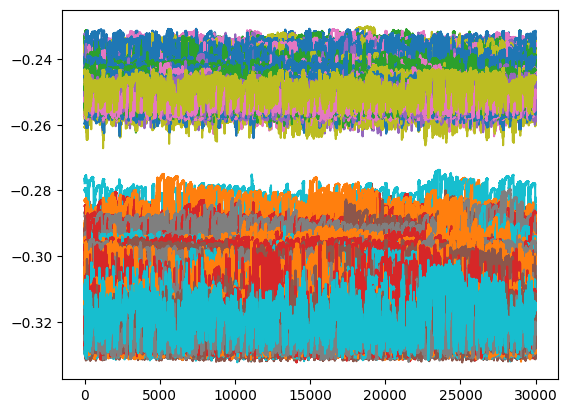

In [57]:
time_stamp = str(datetime.now()).replace(":", "_")
time_stamp = time_stamp.replace(" ", "_")

for i in range(100):
    board = configure_board(SAMPLE_RATE_100MSPS, sample_rate_compute=int(100E6), range_I = INPUT_RANGE_PM_200_MV, range_Q= INPUT_RANGE_PM_200_MV)
    time.sleep(0.1)
    acquire_data_triggeredstreaming(board, r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_" + time_stamp, buffers = 200)
    time.sleep(0.1)
    read_and_downsample(folderpath=r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_"+time_stamp, new_path= r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\solidneon_downsampled_"+ time_stamp, filename = f"{i}_downsampled.csv", bounds_I= 0.2, bounds_Q=0.2)
    time.sleep(0.1)

In [3]:
print(board)

NameError: name 'board' is not defined

3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing 300 buffers. Press <enter> to abort
3000000000 300
Capturing

Exception: Error calling function AlazarPostAsyncBuffer with arguments (2848, 1463510040576, 20000000) : b'ApiBufferOverflow'

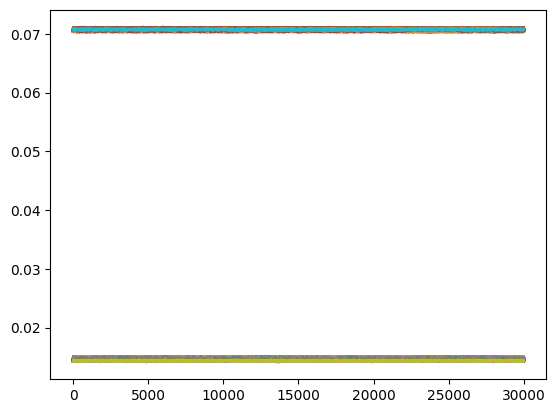

In [20]:
for i in range(6):
    time_stamp = str(datetime.now()).replace(":", "_")
    time_stamp = time_stamp.replace(" ", "_")
    time.sleep(0.5)
    for i in range(100):
        board = configure_board(SAMPLE_RATE_100MSPS, sample_rate_compute=int(100E6), range_I = INPUT_RANGE_PM_40_MV, range_Q= INPUT_RANGE_PM_200_MV)
        time.sleep(0.1)
        acquire_data_triggeredstreaming(board, r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_" + time_stamp, buffers = 200)
        time.sleep(0.1)
        read_and_downsample(folderpath=r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_" + time_stamp, new_path= r"C:\Users\crow104\Desktop\IceT_SD\NoiseMeasurement\Data\noisefloor_downsampled_" + time_stamp, filename = f"{i}_downsampled.csv", bounds_I= 0.04, bounds_Q=0.2)
        time.sleep(0.1)

    time.sleep(5*60)